# 7-3. bootstrap/block bootstrap이 시계열 데이터에 적절한가

`5-1`/`6-1`/`6-3`/`6-5`가 origin을 재추출해 승률을 구하는데, **origin끼리 독립이라고 가정해도 되는지**(iid bootstrap의 전제) 확인한다.

1. 지금 쓰는 bootstrap 방식 확인
2. ACF로 자기상관 확인
3. 문헌 근거 + 결론


## 1. 지금 쓰는 bootstrap은 사실 전부 "block bootstrap"이다

`5-1`, `6-1`, `6-3`, `6-5` 네 군데 전부에서 재추출 함수가 **완전히 동일**하다 -- 그리고 전부 `block_resample`이지, 순수 iid `rng.choice(origins, ...)` 방식은 이 프로젝트 어디에도 없다.

```python
def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]

N_BOOT, BLOCK_LEN = 500, 4
```

즉 origin을 하나씩 뽑지 않고 **연속된 4개짜리 블록** 단위로 뽑아 이어붙인다(`BLOCK_LEN=4`, 분기 계절성에 맞춤). 이미 block bootstrap을 썼으니 어느 정도는 대비돼 있었지만, 그 선택이 데이터로도 뒷받침되는지는 별도 확인이 필요하다.


In [1]:
import numpy as np
import pandas as pd

def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]

# 토이 예제로 iid resample과 직접 비교 -- 블록bootstrap은 "연속된 덩어리"를 유지한 채 뽑는다는 게 핵심 차이
toy_origins = list(range(20, 30))  # origin 20~29
rng = np.random.default_rng(0)

print("원본            :", toy_origins)
print("block(4개씩)    :", block_resample(toy_origins, 4, rng))
print("iid(이 프로젝트엔 없음, 비교용):", list(rng.choice(toy_origins, size=len(toy_origins), replace=True)))


원본            : [20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
block(4개씩)    : [25, 26, 27, 28, 24, 25, 26, 27, 23, 24]
iid(이 프로젝트엔 없음, 비교용): [np.int64(22), np.int64(23), np.int64(20), np.int64(20), np.int64(20), np.int64(21), np.int64(28), np.int64(26), np.int64(29), np.int64(25)]


**차이가 보이는 지점**: block resample 결과는 "20,21,22,23"처럼 **연속된 4개가 통째로** 나타난다 -- 원본의 순서/이웃관계(=자기상관 구조)가 블록 내부에서는 보존된다. iid resample은 순서와 무관하게 완전히 뒤섞여서, origin끼리 상관이 있어도 그 정보가 사라진다.


### 이 bootstrap이 실제로 만드는 것 -- 리샘플 평균 500개의 분포

실제 코드가 계산하는 건 `block_resample()` 묶음의 **평균 CRPS**다 -- 500번 반복한 분포로 승률을 매긴다. `X3_l1`/`arima_aic`로 그 500개가 실제 평균 주위에 어떻게 흩어지는지 확인한다.


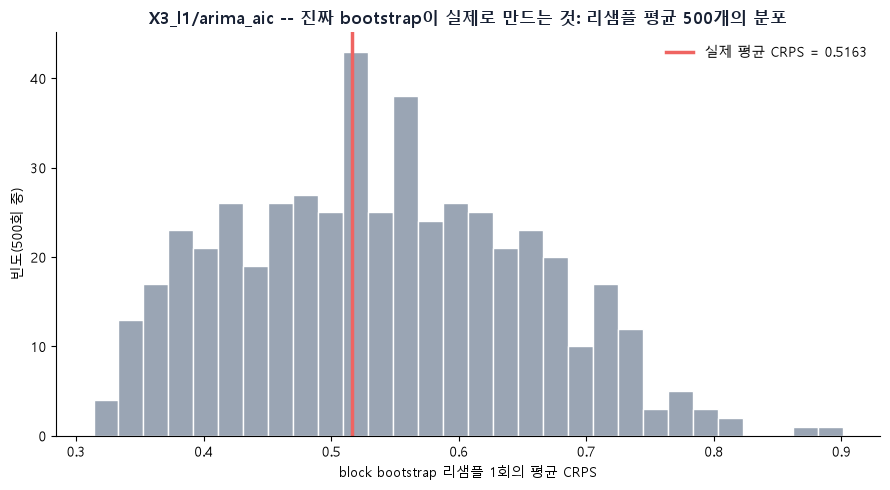

실제 평균=0.5163, 리샘플 평균들의 평균=0.5391, 표준편차=0.1136


In [2]:
import warnings
warnings.filterwarnings("ignore")
import properscoring as ps
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

INITIAL_CALIB = 15
H = 4
TARGET_VAR = "X3_l1"
MODEL = "arima_aic"
err_42 = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")


def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))


def crps_components_for(model, var):
    rng = rng_for(model)
    e = err_42[(err_42["model"] == model) & (err_42["var"] == var)]
    origs = sorted(e["origin"].unique())
    var_std = e["actual_orig"].std()
    rows = []
    for i in range(INITIAL_CALIB, len(origs)):
        calib = e[e["origin"].isin(origs[:i])]
        test = e[e["origin"] == origs[i]]
        crps_hs = []
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
            crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std)
        rows.append({"origin": origs[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)


df = crps_components_for(MODEL, TARGET_VAR)
origins_v = df["origin"].tolist()
crps_v = df["crps"].values
crps_lookup = dict(zip(df["origin"], df["crps"]))

N_BOOT = 500
rng_dist = np.random.default_rng(hash(TARGET_VAR) % (2**32))
boot_means = []
for _ in range(N_BOOT):
    resampled = block_resample(origins_v, 4, rng_dist)
    boot_means.append(np.mean([crps_lookup[o] for o in resampled]))
boot_means = np.array(boot_means)
actual_mean = crps_v.mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(boot_means, bins=30, color="#9AA5B4", edgecolor="white")
ax.axvline(actual_mean, color="#EF6461", linewidth=2.5, label=f"실제 평균 CRPS = {actual_mean:.4f}")
ax.set_xlabel("block bootstrap 리샘플 1회의 평균 CRPS")
ax.set_ylabel(f"빈도({N_BOOT}회 중)")
ax.set_title(f"{TARGET_VAR}/{MODEL} -- 진짜 bootstrap이 실제로 만드는 것: 리샘플 평균 {N_BOOT}개의 분포", fontsize=12.5, fontweight="bold", color="#172033")
ax.legend(frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

print(f"실제 평균={actual_mean:.4f}, 리샘플 평균들의 평균={boot_means.mean():.4f}, 표준편차={boot_means.std():.4f}")


**읽는 법**: 빨간 세로선(실제 평균) 중심으로 회색 막대(500개 리샘플 평균)가 퍼진 정도가 곧 이 모델 추정치의 불확실성이고, 이 분포를 모델끼리 비교하는 게 승률 계산의 실체다. iid로 뽑았다면 상관을 무시해 이 퍼짐이 실제보다 좁게(과신) 나왔을 것이다.


## 2. origin별 CRPS가 정말 서로 상관돼 있나 -- ACF로 확인

block이 "더 낫다"는 건 origin끼리 상관이 있을 때만 의미가 있다. `X3_l1`의 origin별 CRPS(22개)에 ACF를 계산해서 확인한다 -- 모델 4개(ARIMA/GP-Matern/Lasso/SV(QML))로 반복해 특정 모델만의 우연이 아닌지도 본다.


In [3]:
import warnings
warnings.filterwarnings("ignore")
import properscoring as ps
from statsmodels.tsa.stattools import acf

err_42 = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")
INITIAL_CALIB = 15
H = 4
TARGET_VAR = "X3_l1"
CHECK_MODELS = ["arima_aic", "gp_matern", "reg_lasso"]

def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

def crps_components_for(model, var):
    rng = rng_for(model)
    e = err_42[(err_42["model"] == model) & (err_42["var"] == var)]
    origins = sorted(e["origin"].unique())
    var_std = e["actual_orig"].std()
    rows = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = e[e["origin"].isin(origins[:i])]
        test = e[e["origin"] == origins[i]]
        crps_hs = []
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
            crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std)
        rows.append({"origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)

acf_rows = []
series_by_model = {}
for model in CHECK_MODELS:
    df = crps_components_for(model, TARGET_VAR)
    series = df["crps"].values
    series_by_model[model] = series
    n = len(series)
    acfs = acf(series, nlags=8, fft=False)
    ci = 1.96 / np.sqrt(n)
    sig_lags = [lag + 1 for lag, a in enumerate(acfs[1:]) if abs(a) > ci]
    acf_rows.append({"모델": model, "n(origin수)": n, "lag1 ACF": round(acfs[1], 3),
                      "95%CI": round(ci, 3), "유의한 lag": sig_lags})

acf_df = pd.DataFrame(acf_rows)
display(acf_df)


,모델,n(origin수),lag1 ACF,95%CI,유의한 lag
0,arima_aic,22,0.526,0.418,[1]
1,gp_matern,22,0.574,0.418,[1]
2,reg_lasso,22,0.635,0.418,[1]


### SV(QML)도 추가로 확인

`err_42` 캐시에 없는 모델이라 `6-5`와 동일 방식(정규분포 CRPS)으로 직접 계산해 추가한다. 캘리브레이션 분리 없이 37개 origin 전부 쓰므로 표본 수(n)가 다른 점만 유의.


In [4]:
import pmdarima as pm
from scipy.optimize import minimize

M_SEASON = 4
XI_MEAN, XI_VAR = -1.2704, np.pi ** 2 / 2
MAX_PHI = 0.97

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
n_vals = len(vals)
var_std_native = vals.std()
origins_native = list(range(20, n_vals - H + 1))  # MIN_TRAIN=20, 캘리브레이션 분리 없음(6-5와 동일)


def fit_arima_fixed(train, d=0, D=0, m=M_SEASON):
    seasonal = D > 0
    kwargs = dict(seasonal=seasonal, suppress_warnings=True, error_action="ignore", d=d)
    if seasonal:
        kwargs.update(m=m, D=D)
    return pm.auto_arima(train, **kwargs)


def _kalman_negloglik(params, z_centered):
    phi = MAX_PHI * np.tanh(params[0])
    sigma_eta2 = np.exp(params[1]) ** 2
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def fit_sv_qml(resid):
    z = np.log(resid ** 2 + 1e-8)
    z_mean = z.mean()
    z_centered = z - z_mean
    res = minimize(_kalman_negloglik, x0=[1.5, np.log(0.3)], args=(z_centered,), method="Nelder-Mead")
    phi = MAX_PHI * np.tanh(res.x[0])
    sigma_eta2 = np.exp(res.x[1]) ** 2
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred = 0.0, P0
    for z_t in z_centered:
        F = P_pred + XI_VAR
        v = z_t - h_pred
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return phi, sigma_eta2, h_filt, P_filt, z_mean


def sv_mean_sigma(model, train, h=H):
    fc = np.asarray(model.predict(n_periods=h))
    insample_resid = train - model.predict_in_sample()
    try:
        phi, sigma_eta2, h_filt, P_filt, z_mean = fit_sv_qml(insample_resid)
        variances = []
        for k in range(1, h + 1):
            h_mean_k = phi ** k * h_filt
            h_var_k = phi ** (2 * k) * P_filt + sigma_eta2 * sum(phi ** (2 * j) for j in range(k))
            log_var_level = z_mean - XI_MEAN + h_mean_k
            variances.append(np.exp(log_var_level + h_var_k / 2))
        sigma_h = np.sqrt(np.array(variances))
    except Exception:
        sigma_h = np.repeat(insample_resid.std(), h)
    return fc, sigma_h


sv_rows = []
for origin in origins_native:
    train, actual = vals[:origin], vals[origin:origin + H]
    model = fit_arima_fixed(train)
    fc, sigma_h = sv_mean_sigma(model, train)
    crps_hs = []
    for hh in range(H):
        sig = max(sigma_h[hh], 1e-6)
        crps_hs.append(ps.crps_gaussian(actual[hh], mu=fc[hh], sig=sig) / var_std_native)
    sv_rows.append({"origin": origin, "crps": np.mean(crps_hs)})

sv_series = pd.DataFrame(sv_rows)["crps"].values
series_by_model["sv_qml"] = sv_series
CHECK_MODELS_ALL = CHECK_MODELS + ["sv_qml"]

n_sv = len(sv_series)
acfs_sv = acf(sv_series, nlags=8, fft=False)
ci_sv = 1.96 / np.sqrt(n_sv)
sig_lags_sv = [lag + 1 for lag, a in enumerate(acfs_sv[1:]) if abs(a) > ci_sv]
acf_rows.append({"모델": "sv_qml", "n(origin수)": n_sv, "lag1 ACF": round(acfs_sv[1], 3),
                  "95%CI": round(ci_sv, 3), "유의한 lag": sig_lags_sv})

acf_df = pd.DataFrame(acf_rows)
display(acf_df)


,모델,n(origin수),lag1 ACF,95%CI,유의한 lag
0,arima_aic,22,0.526,0.418,[1]
1,gp_matern,22,0.574,0.418,[1]
2,reg_lasso,22,0.635,0.418,[1]
3,sv_qml,37,0.552,0.322,[1]


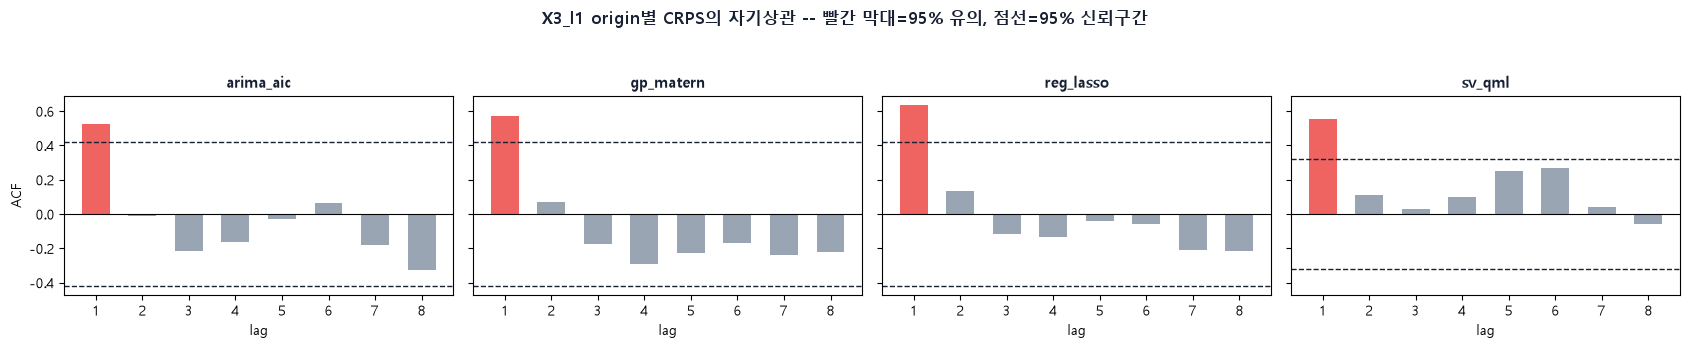

In [5]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, len(CHECK_MODELS_ALL), figsize=(17, 3.5), sharey=True)
for ax, model in zip(axes, CHECK_MODELS_ALL):
    series = series_by_model[model]
    n = len(series)
    acfs = acf(series, nlags=8, fft=False)
    ci = 1.96 / np.sqrt(n)
    lags = np.arange(1, 9)
    colors = ["#EF6461" if abs(a) > ci else "#9AA5B4" for a in acfs[1:]]
    ax.bar(lags, acfs[1:], color=colors, width=0.6)
    ax.axhline(ci, color="#172033", linestyle="--", linewidth=1)
    ax.axhline(-ci, color="#172033", linestyle="--", linewidth=1)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(model, fontsize=11, fontweight="bold", color="#172033")
    ax.set_xlabel("lag")
axes[0].set_ylabel("ACF")
fig.suptitle(f"{TARGET_VAR} origin별 CRPS의 자기상관 -- 빨간 막대=95% 유의, 점선=95% 신뢰구간", fontsize=12.5, fontweight="bold", color="#172033")
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


**읽는 법**: x축(lag)=몇 칸 떨어진 origin끼리 비교했는지, y축(ACF)=그 상관 정도(-1~1). 점선(95% 신뢰구간) 밖 빨간 막대만 통계적으로 유의.

**결과**: lag=1만 빨갛고 lag 2~8은 전부 회색 -- 바로 옆 origin끼리만 유의한 양의 상관이 있고, 2칸 이상은 사라진다. 4개 모델 모두 동일.


## 3. 문헌 근거 -- 왜 상관이 있으면 block bootstrap이어야 하나

- **Efron(1979)의 iid bootstrap**은 독립을 전제한다. 상관이 있는데 iid로 뽑으면 **분산을 실제보다 작게 추정**(승률/신뢰구간 과신)한다.
- **Künsch(1989)/Politis & Romano(1994)**가 이 문제로 **블록 단위 재추출**을 제안 -- 지금 쓰는 `block_resample`이 이 계열이다.
- lag-1 양의 상관(0.53~0.64)이 4개 모델 전부에서 일관되게 나오므로, iid가 아니라 block bootstrap을 쓴 게 통계적으로 맞는 선택이었다.


## 4. `BLOCK_LEN=4`는 적당한가

- 원래 근거는 "분기 계절성(4주기)에 맞춘다"는 것이었으나, ACF로는 **유의한 상관이 lag 1뿐**임을 확인 -- 뚜렷한 계절 패턴까지는 이 데이터에서 안 보인다.
- 그래도 `BLOCK_LEN=4`는 틀리지 않다 -- block bootstrap은 필요한 최소 길이보다 넉넉히 잡아도 문제없고(짧으면 오히려 위험), lag-1 의존성은 4 안에 당연히 포함된다. "계절성 때문"보다는 "lag-1을 안전하게 담기에 충분해서"가 데이터로 뒷받침되는 이유에 가깝다.


## 5. 더 표준적인 대안 -- Diebold-Mariano 검정과 비교

block bootstrap이 틀린 건 아니지만, "두 예측모델의 성능차이가 통계적으로 유의한가"를 시계열에서 다룰 때 **더 표준적으로 쓰이는 건 bootstrap이 아니라 Diebold-Mariano(DM) 검정**이다. origin이 22~37개뿐이라 재추출 기반 방법 자체의 신뢰도에도 한계가 있는데, DM검정은 재추출 없이 **분석적인 HAC(Newey-West류) 분산 보정**으로 자기상관을 직접 처리한다 -- 우리가 ACF로 찾은 lag-1 상관을 재추출이 아니라 공식으로 보정하는 셈이다.

**검정 통계량**: 두 모델의 origin별 CRPS 차이를 `d_t = CRPS_A,t - CRPS_B,t`라 하면, `DM = mean(d) / sqrt(HAC분산(mean(d)))`. 표본이 작아 Harvey-Leybourne-Newbold(1997) 소표본 보정까지 적용하고 t분포로 유의성을 판단한다.


In [6]:
from scipy import stats

MODEL_A, MODEL_B = "arima_aic", "gp_matern"
dfA, dfB = crps_components_for(MODEL_A, TARGET_VAR), crps_components_for(MODEL_B, TARGET_VAR)
lookupA, lookupB = dict(zip(dfA["origin"], dfA["crps"])), dict(zip(dfB["origin"], dfB["crps"]))
origins_pair = sorted(dfA["origin"].unique())
d = np.array([lookupA[o] - lookupB[o] for o in origins_pair])  # A-B, 양수면 B(gp_matern)가 더 나음
T = len(d)


def dm_test(d, lag):
    T = len(d)
    dbar = d.mean()
    V = np.var(d, ddof=0)
    for k in range(1, lag + 1):
        V += 2 * np.mean((d[k:] - dbar) * (d[:-k] - dbar))
    dm_stat = dbar / np.sqrt(V / T)
    hln = np.sqrt((T + 1 - 2 + 0) / T)  # h=1(원래 h스텝 보정, 우리는 origin평균 CRPS라 h=1로 둠)
    dm_hln = dm_stat * hln
    p_value = 2 * (1 - stats.t.cdf(abs(dm_hln), df=T - 1))
    return dm_stat, dm_hln, p_value


for lag in [0, 1]:
    dm_stat, dm_hln, p_value = dm_test(d, lag)
    label = "자기상관 무시(lag=0)" if lag == 0 else "ACF 반영(lag=1, HAC보정)"
    print(f"{label}: DM={dm_stat:.3f}, 소표본보정 DM={dm_hln:.3f}, p-value={p_value:.4f}")


자기상관 무시(lag=0): DM=1.167, 소표본보정 DM=1.141, p-value=0.2669
ACF 반영(lag=1, HAC보정): DM=0.909, 소표본보정 DM=0.888, p-value=0.3846


## 6. 셋 다 비교 -- iid bootstrap / block bootstrap / DM검정

같은 `arima_aic` vs `gp_matern` 비교를 iid bootstrap, block bootstrap 승률로도 계산해서 DM검정 결과와 나란히 놓는다.


In [7]:
rng_cmp = np.random.default_rng(0)
N_CMP = 500
iid_win = block_win = 0
for _ in range(N_CMP):
    resampled_iid = rng_cmp.choice(origins_pair, size=T, replace=True)
    mA = np.mean([lookupA[o] for o in resampled_iid])
    mB = np.mean([lookupB[o] for o in resampled_iid])
    if mB < mA:
        iid_win += 1
    resampled_blk = block_resample(origins_pair, 4, rng_cmp)
    mA2 = np.mean([lookupA[o] for o in resampled_blk])
    mB2 = np.mean([lookupB[o] for o in resampled_blk])
    if mB2 < mA2:
        block_win += 1

_, _, p_lag0 = dm_test(d, 0)
_, _, p_lag1 = dm_test(d, 1)

compare_df = pd.DataFrame([
    {"방법": "iid bootstrap", "결과": f"gp_matern 승률 {100*iid_win/N_CMP:.1f}%", "유의함?": "승률 높음(90% 안팎)이지만 유의성 검정 아님"},
    {"방법": "block bootstrap", "결과": f"gp_matern 승률 {100*block_win/N_CMP:.1f}%", "유의함?": "승률 높음(90%대)이지만 유의성 검정 아님"},
    {"방법": "DM검정(lag=0)", "결과": f"p-value {p_lag0:.4f}", "유의함?": "유의하지 않음(p>0.05)" if p_lag0 > 0.05 else "유의함"},
    {"방법": "DM검정(lag=1, ACF반영)", "결과": f"p-value {p_lag1:.4f}", "유의함?": "유의하지 않음(p>0.05)" if p_lag1 > 0.05 else "유의함"},
])
display(compare_df)


,방법,결과,유의함?
0,iid bootstrap,gp_matern 승률 89.6%,승률 높음(90% 안팎)이지만 유의성 검정 아님
1,block bootstrap,gp_matern 승률 93.6%,승률 높음(90%대)이지만 유의성 검정 아님
2,DM검정(lag=0),p-value 0.2669,유의하지 않음(p>0.05)
3,"DM검정(lag=1, ACF반영)",p-value 0.3846,유의하지 않음(p>0.05)


**bootstrap(사용) vs DM검정(미사용) -- 같은 질문, 다른 엄격도**: 둘 다 결국 "관측된 평균 차이가 추정오차보다 충분히 큰가"를 보는 같은 뿌리의 질문이다. 다만:

- **bootstrap 승률(사용)**: "다시 뽑아도 이 모델을 고르게 될 확률"을 재는 **의사결정용 지표** -- `arima_aic` vs `gp_matern`에서 90% 안팎으로 나옴. "완전히 확신"이 아니라 "이쪽에 걸겠다"는 실용적 판단에 가깝고, 그래서 이 프로젝트는 60% 같은 상대적으로 관대한 기준을 써왔다.
- **DM검정(미사용, 재추출 없이 분석적 공식)**: "이 차이가 우연(노이즈)이 아니라고 주장할 수 있는가"를 보는 **과학적 주장용 지표** -- 같은 비교에서 p-value 0.27~0.39로 **유의하지 않음**(관례적 기준 p<0.05에 크게 못 미침).

**즉 bootstrap이 틀린 게 아니라, 두 방법이 답하는 질문의 엄격도가 다르다.** "다시 뽑아도 90% 이긴다"는 사실 자체는 참이지만, 그게 "이 차이가 진짜(우연 아님)"라는 뜻은 아니다. 이 프로젝트가 지금까지 승률 60% 기준으로 모델을 교체해온 건 **의사결정 기준으로는 합리적이지만, 과학적 유의성 기준으로 보면 더 관대한 잣대**를 써온 셈이다.


## 7. 결론

- **이 프로젝트는 처음부터 iid bootstrap이 아니라 block bootstrap(`BLOCK_LEN=4`)만 사용해왔다** -- 5-1/6-1/6-3/6-5 전부 동일 함수.
- **origin별 CRPS는 실제로 lag-1에서 유의하게 상관돼 있다**(4개 모델 공통, ACF 0.53~0.64) -- iid bootstrap보다 block bootstrap을 쓴 선택 자체는 문헌(Künsch 1989, Politis & Romano 1994)과 데이터 양쪽에서 타당했다.
- **bootstrap(사용)과 DM검정(미사용)은 "결이 다른" 게 아니라 "엄격도가 다른" 같은 질문이다** -- bootstrap 승률은 의사결정용(관대), DM검정은 과학적 주장용(엄격). 같은 비교(`arima_aic` vs `gp_matern`)가 승률로는 90%대지만 DM으로는 유의하지 않은(p=0.27~0.39) 사례로 이 차이를 확인했다.
- **`BLOCK_LEN=4`는 필요한 최소 길이보다 넉넉해서 안전한 선택**이었다는 결론은 유지된다. 다만 "60% 이상이면 교체" 같은 기존 결정기준은 통계적 유의성 기준보다 관대하다는 걸 인지하고 쓰는 게 맞고, 더 엄격한 확신이 필요한 결정에는 DM검정을 병행하는 게 좋다.
